In [58]:
import numpy as np
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [59]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")

In [60]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [61]:
#tokenizer
vocab_size = 1000
min_frequency = 2
corpus = [text for text in dataset["train"]["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [62]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [63]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [64]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [65]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [66]:
classifiers = OrderedDict()

In [67]:
token_indicator_encoder = TokenIndicator(tokenizer)

In [68]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [69]:
bow_encoder = BagOfWords(tokenizer)

classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [74]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.075 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0188 | train acc: 0.4648 | val loss: 0.9946 | val acc: 0.4366
Epoch 02 | train loss: 0.8687 | train acc: 0.6338 | val loss: 0.9522 | val acc: 0.4366
Epoch 03 | train loss: 0.7655 | train acc: 0.6021 | val loss: 0.9414 | val acc: 0.4366
Epoch 04 | train loss: 0.6752 | train acc: 0.6444 | val loss: 0.9391 | val acc: 0.4366
Epoch 05 | train loss: 0.6081 | train acc: 0.7535 | val loss: 0.9392 | val acc: 0.4507
Epoch 06 | train loss: 0.5351 | train acc: 0.8697 | val loss: 0.9393 | val acc: 0.4507
Epoch 07 | train loss: 0.4671 | train acc: 0.9331 | val loss: 0.9419 | val acc: 0.4930
Epoch 08 | train loss: 0.4025 | train acc: 0.9472 | val loss: 0.9424 | val acc: 0.5211
Epoch 09 | train loss: 0.3440 | train acc: 0.9542 | val loss: 0.9439 | val acc: 0.5634
Epoch 10 | train loss: 0.2863 | train acc: 0.9648 | val loss: 0.9474 | val acc: 0.5775
Epoch 11 | train loss: 0.2335 | train acc: 0.9648 | val loss: 0.9624 | val acc: 0.5775
Epoch 12 | train loss: 0.1961 | train acc: 

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0248 | train acc: 0.4683 | val loss: 0.9220 | val acc: 0.7324
Epoch 02 | train loss: 0.8904 | train acc: 0.6725 | val loss: 0.8334 | val acc: 0.7465
Epoch 03 | train loss: 0.7940 | train acc: 0.7289 | val loss: 0.7660 | val acc: 0.7746
Epoch 04 | train loss: 0.7092 | train acc: 0.8063 | val loss: 0.7216 | val acc: 0.8169
Epoch 05 | train loss: 0.6365 | train acc: 0.8838 | val loss: 0.6936 | val acc: 0.8028
Epoch 06 | train loss: 0.5613 | train acc: 0.9155 | val loss: 0.6758 | val acc: 0.7746
Epoch 07 | train loss: 0.4948 | train acc: 0.9437 | val loss: 0.6649 | val acc: 0.7465
Epoch 08 | train loss: 0.4206 | train acc: 0.9507 | val loss: 0.6524 | val acc: 0.7465
Epoch 09 | train loss: 0.3563 | train acc: 0.9613 | val loss: 0.6392 | val acc: 0.7324
Epoch 10 | train loss: 0.3028 | train acc: 0.9648 | val loss: 0.6255 | val acc: 0.7324
Epoch 11 | train loss: 0.2491 | train acc: 0.9613 | val loss: 0.6233 | val acc: 0.7183
Epoch 12 | train loss: 0.2047 | train acc: 

... (2 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0907 | train acc: 0.3768 | val loss: 1.0010 | val acc: 0.6197
Epoch 02 | train loss: 0.9377 | train acc: 0.6338 | val loss: 0.9062 | val acc: 0.5775
Epoch 03 | train loss: 0.8242 | train acc: 0.6549 | val loss: 0.8390 | val acc: 0.5634
Epoch 04 | train loss: 0.7404 | train acc: 0.6937 | val loss: 0.7921 | val acc: 0.5634
Epoch 05 | train loss: 0.6633 | train acc: 0.7500 | val loss: 0.7566 | val acc: 0.5915
Epoch 06 | train loss: 0.5944 | train acc: 0.8380 | val loss: 0.7250 | val acc: 0.6901
Epoch 07 | train loss: 0.5257 | train acc: 0.9190 | val loss: 0.6979 | val acc: 0.7183
Epoch 08 | train loss: 0.4526 | train acc: 0.9366 | val loss: 0.6702 | val acc: 0.7606
Epoch 09 | train loss: 0.3912 | train acc: 0.9472 | val loss: 0.6451 | val acc: 0.7606
Epoch 10 | train loss: 0.3349 | train acc: 0.9542 | val loss: 0.6200 | val acc: 0.7606
Epoch 11 | train loss: 0.2800 | train acc: 0.9613 | val loss: 0.6011 | val acc: 0.7606
Epoch 12 | train loss: 0.2379 | train acc: 

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0597 | train acc: 0.4120 | val loss: 0.9659 | val acc: 0.5493
Epoch 02 | train loss: 0.9105 | train acc: 0.7359 | val loss: 0.8678 | val acc: 0.5634
Epoch 03 | train loss: 0.8089 | train acc: 0.7218 | val loss: 0.7987 | val acc: 0.5493
Epoch 04 | train loss: 0.7148 | train acc: 0.7359 | val loss: 0.7511 | val acc: 0.5634
Epoch 05 | train loss: 0.6440 | train acc: 0.7606 | val loss: 0.7130 | val acc: 0.5634
Epoch 06 | train loss: 0.5699 | train acc: 0.8592 | val loss: 0.6848 | val acc: 0.5915
Epoch 07 | train loss: 0.4985 | train acc: 0.9190 | val loss: 0.6628 | val acc: 0.6197
Epoch 08 | train loss: 0.4317 | train acc: 0.9472 | val loss: 0.6450 | val acc: 0.6620
Epoch 09 | train loss: 0.3640 | train acc: 0.9542 | val loss: 0.6330 | val acc: 0.6479
Epoch 10 | train loss: 0.3073 | train acc: 0.9648 | val loss: 0.6247 | val acc: 0.6620
Epoch 11 | train loss: 0.2577 | train acc: 0.9648 | val loss: 0.6212 | val acc: 0.6761
Epoch 12 | train loss: 0.2168 | train acc: 

In [75]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 50,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.067 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1522 | train acc: 0.1338 | val loss: 1.0797 | val acc: 0.3944
Epoch 02 | train loss: 0.9767 | train acc: 0.7359 | val loss: 1.0062 | val acc: 0.5070
Epoch 03 | train loss: 0.8450 | train acc: 0.7993 | val loss: 0.9583 | val acc: 0.4789
Epoch 04 | train loss: 0.7357 | train acc: 0.7993 | val loss: 0.9365 | val acc: 0.4507
Epoch 05 | train loss: 0.6477 | train acc: 0.8028 | val loss: 0.9324 | val acc: 0.4366
Epoch 06 | train loss: 0.5731 | train acc: 0.8768 | val loss: 0.9297 | val acc: 0.4789
Epoch 07 | train loss: 0.5072 | train acc: 0.9155 | val loss: 0.9286 | val acc: 0.5352
Epoch 08 | train loss: 0.4452 | train acc: 0.9472 | val loss: 0.9267 | val acc: 0.5915
Epoch 09 | train loss: 0.3826 | train acc: 0.9507 | val loss: 0.9267 | val acc: 0.6056
Epoch 10 | train loss: 0.3214 | train acc: 0.9718 | val loss: 0.9253 | val acc: 0.6056
Epoch 11 | train loss: 0.2743 | train acc: 0.9683 | val loss: 0.9244 | val acc: 0.6056
Epoch 12 | train loss: 0.2272 | train acc: 

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0133 | train acc: 0.5070 | val loss: 0.9174 | val acc: 0.6197
Epoch 02 | train loss: 0.8850 | train acc: 0.6620 | val loss: 0.8321 | val acc: 0.6197
Epoch 03 | train loss: 0.7797 | train acc: 0.7711 | val loss: 0.7705 | val acc: 0.6901
Epoch 04 | train loss: 0.6984 | train acc: 0.8239 | val loss: 0.7334 | val acc: 0.7042
Epoch 05 | train loss: 0.6192 | train acc: 0.8979 | val loss: 0.7092 | val acc: 0.7183
Epoch 06 | train loss: 0.5408 | train acc: 0.9261 | val loss: 0.6874 | val acc: 0.7183
Epoch 07 | train loss: 0.4729 | train acc: 0.9366 | val loss: 0.6725 | val acc: 0.6901
Epoch 08 | train loss: 0.4036 | train acc: 0.9507 | val loss: 0.6620 | val acc: 0.7042
Epoch 09 | train loss: 0.3416 | train acc: 0.9577 | val loss: 0.6604 | val acc: 0.7042
Epoch 10 | train loss: 0.2909 | train acc: 0.9648 | val loss: 0.6502 | val acc: 0.7183
Epoch 11 | train loss: 0.2398 | train acc: 0.9648 | val loss: 0.6432 | val acc: 0.7042
Epoch 12 | train loss: 0.1983 | train acc: 

... (2 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0403 | train acc: 0.4824 | val loss: 0.9506 | val acc: 0.6056
Epoch 02 | train loss: 0.8975 | train acc: 0.6866 | val loss: 0.8738 | val acc: 0.6197
Epoch 03 | train loss: 0.7963 | train acc: 0.6831 | val loss: 0.8220 | val acc: 0.6056
Epoch 04 | train loss: 0.7179 | train acc: 0.7148 | val loss: 0.7830 | val acc: 0.6056
Epoch 05 | train loss: 0.6478 | train acc: 0.8204 | val loss: 0.7520 | val acc: 0.6620
Epoch 06 | train loss: 0.5741 | train acc: 0.8697 | val loss: 0.7251 | val acc: 0.7324
Epoch 07 | train loss: 0.5085 | train acc: 0.9261 | val loss: 0.7004 | val acc: 0.7465
Epoch 08 | train loss: 0.4352 | train acc: 0.9542 | val loss: 0.6803 | val acc: 0.7183
Epoch 09 | train loss: 0.3872 | train acc: 0.9472 | val loss: 0.6609 | val acc: 0.7324
Epoch 10 | train loss: 0.3255 | train acc: 0.9577 | val loss: 0.6474 | val acc: 0.7324
Epoch 11 | train loss: 0.2706 | train acc: 0.9683 | val loss: 0.6371 | val acc: 0.7465
Epoch 12 | train loss: 0.2311 | train acc: 

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0297 | train acc: 0.5317 | val loss: 0.9332 | val acc: 0.5352
Epoch 02 | train loss: 0.8910 | train acc: 0.5951 | val loss: 0.8443 | val acc: 0.5493
Epoch 03 | train loss: 0.7894 | train acc: 0.6197 | val loss: 0.7792 | val acc: 0.5493
Epoch 04 | train loss: 0.7016 | train acc: 0.7007 | val loss: 0.7270 | val acc: 0.6056
Epoch 05 | train loss: 0.6367 | train acc: 0.7958 | val loss: 0.6845 | val acc: 0.6197
Epoch 06 | train loss: 0.5564 | train acc: 0.8838 | val loss: 0.6563 | val acc: 0.6338
Epoch 07 | train loss: 0.4864 | train acc: 0.9155 | val loss: 0.6323 | val acc: 0.6761
Epoch 08 | train loss: 0.4157 | train acc: 0.9331 | val loss: 0.6144 | val acc: 0.6901
Epoch 09 | train loss: 0.3543 | train acc: 0.9401 | val loss: 0.5967 | val acc: 0.7042
Epoch 10 | train loss: 0.2948 | train acc: 0.9613 | val loss: 0.5844 | val acc: 0.7042
Epoch 11 | train loss: 0.2489 | train acc: 0.9577 | val loss: 0.5778 | val acc: 0.6620
Epoch 12 | train loss: 0.2143 | train acc: 

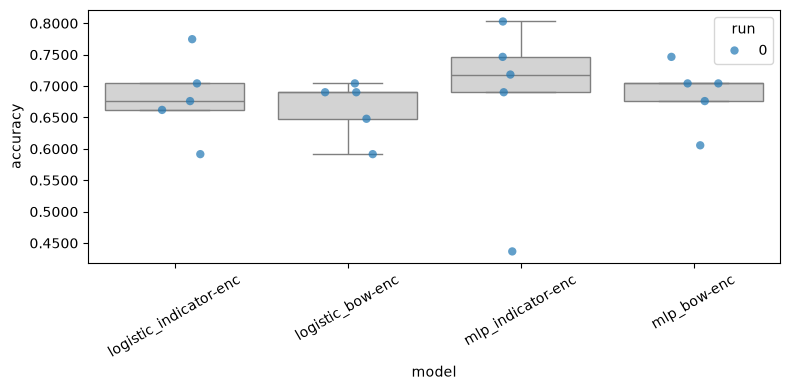

In [76]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))